# Session 1: Probability Basics

*ECE 225A, Module 01 (Probability Review), slides 1-12*

The review starts by building a shared vocabulary for the rest of the course. This session covers how to turn a random experiment into a mathematical model, how to compute probabilities when every outcome is equally likely, and how to count the outcomes that matter. Cards and poker hands are the running example because they force you to be precise about *what* is being counted.

## Learning objectives

After this session you should be able to:

1. Model an experiment as a sample space, a collection of events, and a probability.
2. Recognize an equiprobable space and compute $P(E) = |E|/|\Omega|$.
3. Build sample spaces as Cartesian products and count them with the product rule.
4. Classify a selection as ordered or unordered, with or without replacement, and pick the matching counting formula.
5. Compute poker hand probabilities by counting, and confirm them by simulation.
6. Shortcut a count with a one-to-one correspondence or a symmetry argument.

## Prerequisites

- Set notation: elements, subsets, and the size $|A|$ of a finite set.
- Factorials $n! = n(n-1)\cdots 1$ (binomial coefficients are reviewed below).
- Basic Python and NumPy.

In [1]:
from fractions import Fraction
from math import comb, perm, factorial
from itertools import product, permutations, combinations, combinations_with_replacement

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(225)

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, p):
    # Print a probability as an exact fraction and as a decimal.
    print(f"{label}: {p} = {float(p):.6f}")

## 1. The probability model: experiment, outcomes, events (slide 3)

**Intuition.** Before computing anything, decide what a single run of the experiment can produce. Each possible result is an *outcome*. A yes/no question you care about ("is the roll even?") picks out the outcomes for which the answer is yes; that set is an *event*. The event happens exactly when the realized outcome lands inside it.

**Formal definitions.**

- An *experiment* is a procedure whose result is uncertain.
- An *outcome* $x$ is one possible result. Lowercase $x, y$ denote specific outcomes.
- The *sample space* $\Omega$ is the set of all possible outcomes.
- An *event* is a subset $E \subseteq \Omega$, usually named $E, F$.
- The *random outcome* is written in uppercase, $X$. Event $E$ *occurs* when $X \in E$.
- A *probability* gives each outcome a weight $P(x) \ge 0$ with $\sum_{x \in \Omega} P(x) = 1$. The probability of an event is the total weight inside it:

$$P(E) = \sum_{x \in E} P(x).$$

A probability model is therefore the triple (sample space, events, probability), and *modeling* means choosing those three objects so they match the real experiment.

**Example (one die).** Roll a six-sided die, so $\Omega = \lbrace 1, 2, 3, 4, 5, 6 \rbrace$. "The roll is even" is the event $E = \lbrace 2, 4, 6 \rbrace$, and "the roll is a perfect square" is $F = \lbrace 1, 4 \rbrace$. If the die shows $X = 4$, both events occur. If $X = 3$, neither does. If $X = 1$, only $F$ occurs.

In [2]:
omega = {1, 2, 3, 4, 5, 6}
events = {"even": {2, 4, 6}, "square": {1, 4}}
assert all(E <= omega for E in events.values())   # events are subsets of omega

for x in sorted(omega):
    print(f"X = {x}: occurs ->", [name for name, E in events.items() if x in E])

X = 1: occurs -> ['square']
X = 2: occurs -> ['even']
X = 3: occurs -> []
X = 4: occurs -> ['even', 'square']
X = 5: occurs -> []
X = 6: occurs -> ['even']


**Python check.** Give every face weight $1/6$, confirm the weights sum to 1, and compute $P(E)$ as a sum of weights, exactly as in the definition. (Models with unequal weights, such as a loaded die, appear in Session 2.)

In [3]:
weight = {x: Fraction(1, 6) for x in omega}
assert sum(weight.values()) == 1


def P(E):
    return sum(weight[x] for x in E)


show("P(even)  ", P(events["even"]))
show("P(square)", P(events["square"]))

P(even)  : 1/2 = 0.500000
P(square): 1/3 = 0.333333


## 2. Equiprobable (uniform) spaces (slide 4)

**Intuition.** When the physics of the experiment favors no outcome (a fair die, a well-shuffled deck), every outcome gets the same weight. Probability then reduces to counting: the share of outcomes that belong to the event.

**Formal definition.** A finite sample space is *equiprobable* (uniform) when every outcome has the same probability. Since the weights sum to 1,

$$P(x) = \frac{1}{|\Omega|} \quad \text{for every } x \in \Omega, \qquad P(E) = \sum_{x \in E} \frac{1}{|\Omega|} = \frac{|E|}{|\Omega|}.$$

**Example (one die), step by step.** $|\Omega| = 6$.

| Event | Set | Size | Probability |
|---|---|---|---|
| Even | {2, 4, 6} | 3 | 3/6 = 1/2 |
| Perfect square | {1, 4} | 2 | 2/6 = 1/3 |

Reading: $P(\text{even}) = 1/2$ is the probability that $X$ is 2, 4, or 6.

In [4]:
even, square = events["even"], events["square"]
show("P(even)   = |E|/|Omega|", Fraction(len(even), len(omega)))
show("P(square) = |F|/|Omega|", Fraction(len(square), len(omega)))

P(even)   = |E|/|Omega|: 1/2 = 0.500000
P(square) = |F|/|Omega|: 1/3 = 0.333333


**Monte Carlo check.** Roll a simulated fair die many times. The fraction of rolls that land in each event should be close to the exact probability.

In [5]:
rolls = rng.integers(1, 7, size=100_000)
print(f"even:   simulated {np.isin(rolls, list(even)).mean():.4f}   exact {1/2:.4f}")
print(f"square: simulated {np.isin(rolls, list(square)).mean():.4f}   exact {1/3:.4f}")

even:   simulated 0.4995   exact 0.5000
square: simulated 0.3348   exact 0.3333


The plot shows the running fraction of even rolls. Early on it swings widely, then it settles near $1/2$. This "long-run fraction" reading of probability is made precise later in the course.

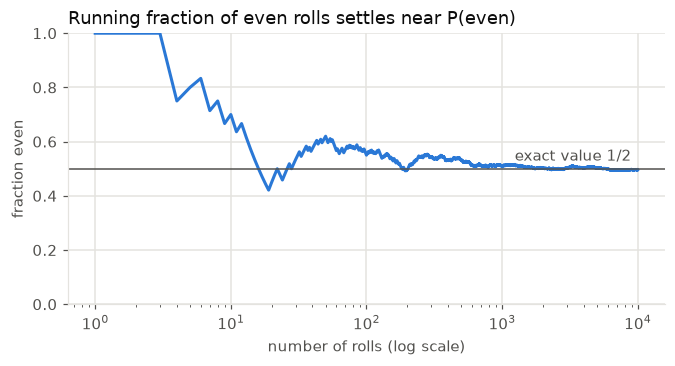

In [6]:
n = np.arange(1, 10_001)
running = np.cumsum(np.isin(rolls[:10_000], list(even))) / n

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(n, running, color=BLUE, lw=2)
ax.axhline(0.5, color=MUTED, lw=1)
ax.text(9_000, 0.53, "exact value 1/2", ha="right", color=MUTED)
ax.set_xscale("log")
ax.set(xlabel="number of rolls (log scale)", ylabel="fraction even", ylim=(0, 1))
ax.set_title("Running fraction of even rolls settles near P(even)", color=INK, loc="left")
plt.show()

## 3. Cards and the deck as a Cartesian product (slides 5-6)

**Intuition.** A standard deck has 4 suits (clubs, diamonds, hearts, spades) and 13 ranks: the ace, the number cards 2 through 10, and the face cards jack, queen, king. There are no jokers in poker. Every (suit, rank) combination appears exactly once, so the deck is a grid of 4 rows and 13 columns.

**Formal definition.** The *Cartesian product* of sets $A$ and $B$ is the set of ordered pairs

$$A \times B = \lbrace (a, b) : a \in A, \ b \in B \rbrace, \qquad |A \times B| = |A| \cdot |B|.$$

More generally (the *product rule*), if a choice is made in $k$ stages with $n_1, n_2, \dots, n_k$ options at each stage, the number of possible results is $n_1 n_2 \cdots n_k$.

**Example.** The deck is $\text{Suits} \times \text{Ranks}$, so the number of cards is $4 \times 13 = 52$.

In [7]:
RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K", "A"]
SUITS = ["clubs", "diamonds", "hearts", "spades"]
deck = list(product(SUITS, RANKS))   # card number c corresponds to deck[c]

assert len(deck) == len(SUITS) * len(RANKS) == 52
print(len(deck), "cards. First three:", deck[:3], " Last:", deck[-1])

52 cards. First three: [('clubs', '2'), ('clubs', '3'), ('clubs', '4')]  Last: ('spades', 'A')


The ace is listed last (high) here; in a straight it can also play low (Section 9). Card number $c$ has rank index $c \bmod 13$ and suit index $\lfloor c / 13 \rfloor$, which the simulations below use.

**Product spaces beyond cards: a modeling trap with two dice.** Roll two dice and look at the sum. It is tempting to take $\Omega = \lbrace 2, 3, \dots, 12 \rbrace$ and say each sum has probability $1/11$. That model is wrong because those 11 outcomes are not equally likely. The right equiprobable space is the product $\lbrace 1, \dots, 6 \rbrace \times \lbrace 1, \dots, 6 \rbrace$ of 36 *ordered* pairs. Then the sum 7 comes from 6 pairs, (1,6), (2,5), ..., (6,1), so $P(\text{sum} = 7) = 6/36 = 1/6$, while the sum 2 comes only from (1,1), so $P(\text{sum} = 2) = 1/36$.

In [8]:
two_dice = list(product(range(1, 7), repeat=2))   # 36 equally likely ordered pairs
sums = [a + b for a, b in two_dice]
print({s: str(Fraction(sums.count(s), 36)) for s in range(2, 13)})

{2: '1/36', 3: '1/18', 4: '1/12', 5: '1/9', 6: '5/36', 7: '1/6', 8: '5/36', 9: '1/9', 10: '1/12', 11: '1/18', 12: '1/36'}


In [9]:
sim = rng.integers(1, 7, size=(100_000, 2)).sum(axis=1)
for s in (2, 7):
    print(f"sum = {s}: simulated {np.mean(sim == s):.4f}   exact {sums.count(s) / 36:.4f}   naive 1/11 = {1/11:.4f}")

sum = 2: simulated 0.0280   exact 0.0278   naive 1/11 = 0.0909
sum = 7: simulated 0.1661   exact 0.1667   naive 1/11 = 0.0909


## 4. Drawing a single card (slide 7)

**Intuition.** Shuffle the deck well and pick one card. No card is favored, so this is an equiprobable experiment.

**Formal model.** $\Omega$ is the deck, $|\Omega| = 52$, and

$$P(\text{2 of hearts}) = P(\text{5 of clubs}) = \cdots = P(\text{king of spades}) = \frac{1}{|\Omega|} = \frac{1}{52}.$$

**Monte Carlo check.** Draw 520,000 cards (with the deck reshuffled each time) and look at how often each of the 52 cards appears. Every frequency should be close to $1/52 \approx 0.01923$.

In [10]:
draws = rng.integers(0, 52, size=520_000)          # card numbers 0..51
freq = np.bincount(draws, minlength=52) / len(draws)
print(f"exact 1/52 = {1/52:.5f};  simulated frequencies range from {freq.min():.5f} to {freq.max():.5f}")

exact 1/52 = 0.01923;  simulated frequencies range from 0.01884 to 0.01968


## 5. Events for a single card (slide 8)

**Intuition.** Once the space is equiprobable, the probability of a card event is the fraction of the deck it covers. Using the grid structure often gives the answer at a glance.

**Formal rule.** $P(E) = |E| / 52$.

**Example, step by step.**

| Event | Occurs when | Size | Probability | Grid reading |
|---|---|---|---|---|
| Heart | the card is a heart | 13 | 13/52 = 1/4 | one of the 4 suits |
| King | the card is a king | 4 | 4/52 = 1/13 | one of the 13 ranks in each suit |
| Face card | the card is J, Q, or K | 3 x 4 = 12 | 12/52 = 3/13 | 3 of the 13 ranks in each suit |

The face-card count is itself a product: 3 ranks times 4 suits.

In [11]:
card_events = {
    "heart":     lambda card: card[0] == "hearts",
    "king":      lambda card: card[1] == "K",
    "face card": lambda card: card[1] in {"J", "Q", "K"},
}
for name, test in card_events.items():
    size = sum(test(card) for card in deck)
    show(f"P({name}) = {size}/52", Fraction(size, 52))

P(heart) = 13/52: 1/4 = 0.250000
P(king) = 4/52: 1/13 = 0.076923
P(face card) = 12/52: 3/13 = 0.230769


In [12]:
sample = [deck[c] for c in draws[:100_000]]
for name, test in card_events.items():
    exact = sum(test(card) for card in deck) / 52
    print(f"{name:9s} simulated {np.mean([test(card) for card in sample]):.4f}   exact {exact:.4f}")

heart     simulated 0.2491   exact 0.2500
king      simulated 0.0779   exact 0.0769
face card simulated 0.2308   exact 0.2308


## 6. Hands: when order does not matter (slide 9)

**Intuition.** Most card games deal you several cards, a *hand*, and only *which* cards you hold matters, not the order they arrived in. So {A, J, Q, K, 10} and {K, 10, Q, A, J} are the same hand. The hand size depends on the game: 13 in bridge, 11 in canasta, 5 in poker.

**Formal definition.** A $k$-card hand is a $k$-element subset of the deck. The number of $k$-element subsets of an $n$-element set is the *binomial coefficient*

$$\binom{n}{k} = \frac{n!}{k!(n-k)!}.$$

**Example.** A hand written in two different orders is the same set, and its $5! = 120$ orderings all collapse to that one set.

In [13]:
hand_a = frozenset([("spades", "A"), ("hearts", "J"), ("clubs", "Q"), ("hearts", "K"), ("diamonds", "10")])
hand_b = frozenset([("hearts", "K"), ("diamonds", "10"), ("clubs", "Q"), ("spades", "A"), ("hearts", "J")])
print("same hand:", hand_a == hand_b)

orderings = list(permutations(hand_a))
print(len(orderings), "orderings, all the same set:", all(frozenset(o) == hand_a for o in orderings))

same hand: True
120 orderings, all the same set: True


In [14]:
for game, k in [("poker", 5), ("bridge", 13)]:
    print(f"{game:6s} ({k:2d} cards): C(52, {k}) = {comb(52, k):,} possible hands")

poker  ( 5 cards): C(52, 5) = 2,598,960 possible hands
bridge (13 cards): C(52, 13) = 635,013,559,600 possible hands


## 7. Counting toolkit: ordered vs unordered selection

This section collects the counting rules behind slides 6, 9, and 10 in one place.

**Intuition.** To count the ways of picking $k$ items from $n$ distinct items, answer two questions:

1. **Does order matter?** A sequence (first, second, ...) or just a set?
2. **Is replacement allowed?** Can the same item be picked more than once?

**Formal summary.**

| | Order matters (sequences) | Order does not matter (sets or multisets) |
|---|---|---|
| **With replacement** | $n^k$ | $\binom{n+k-1}{k}$ |
| **Without replacement** | $\dfrac{n!}{(n-k)!} = n(n-1)\cdots(n-k+1)$ | $\binom{n}{k} = \dfrac{n!}{k!(n-k)!}$ |

- $n^k$: product rule, $n$ options at each of $k$ stages.
- $n!/(n-k)!$: product rule with one fewer option at each stage.
- $\binom{n}{k}$: each $k$-set can be listed in $k!$ orders, so divide the ordered count by $k!$:

$$\binom{n}{k} = \frac{n!/(n-k)!}{k!}.$$

- $\binom{n+k-1}{k}$: a multiset is a list of $k$ stars split by $n-1$ bars into $n$ bins; choose which $k$ of the $n+k-1$ slots hold stars.

**Example.** Pick $k = 3$ from $n = 5$ items. Brute-force enumeration with `itertools` matches each formula.

In [15]:
n, k = 5, 3
items = range(n)
cases = {
    "ordered,   with replacement":    (product(items, repeat=k), n**k),
    "ordered,   without replacement": (permutations(items, k), perm(n, k)),
    "unordered, without replacement": (combinations(items, k), comb(n, k)),
    "unordered, with replacement":    (combinations_with_replacement(items, k), comb(n + k - 1, k)),
}
for case, (generator, formula) in cases.items():
    print(f"{case}: brute force {len(list(generator)):3d}   formula {formula:3d}")

ordered,   with replacement: brute force 125   formula 125
ordered,   without replacement: brute force  60   formula  60
unordered, without replacement: brute force  10   formula  10
unordered, with replacement: brute force  35   formula  35


**Which outcomes are equally likely?** Counting and probability only agree when you count in a space whose outcomes are equally likely.

- Without replacement (dealing cards), ordered sequences are equally likely and so are unordered sets. Either works, as long as the numerator and denominator use the *same* convention.
- With replacement (rolling dice), ordered sequences are equally likely but multisets are **not**. The multiset {1, 1} arises from one ordered pair, (1,1), while {1, 2} arises from two, (1,2) and (2,1).

In [16]:
pairs = list(product(range(1, 7), repeat=2))
show("P(two dice show the multiset {1,1})", Fraction(sum(sorted(p) == [1, 1] for p in pairs), 36))
show("P(two dice show the multiset {1,2})", Fraction(sum(sorted(p) == [1, 2] for p in pairs), 36))

P(two dice show the multiset {1,1}): 1/36 = 0.027778
P(two dice show the multiset {1,2}): 1/18 = 0.055556


## 8. The space of poker hands (slide 10)

**Intuition.** A poker hand is a 5-card subset of the 52-card deck. A good shuffle makes every subset equally likely, so every poker probability is a count divided by the number of possible hands.

**Formal model.** $\Omega = \lbrace \text{all 5-card subsets of the deck} \rbrace$, equiprobable, with

$$|\Omega| = \binom{52}{5} = \frac{52!}{5! \cdot 47!} = \frac{52 \cdot 51 \cdot 50 \cdot 49 \cdot 48}{5 \cdot 4 \cdot 3 \cdot 2 \cdot 1}.$$

**Step by step.** Cancel before multiplying: $50 / 5 = 10$ and $48 / (4 \cdot 3 \cdot 2) = 2$, leaving

$$|\Omega| = 52 \cdot 51 \cdot 10 \cdot 49 \cdot 2 = 2{,}598{,}960 \approx 2.6 \text{ million}.$$

A quick mental estimate: $52 \cdot 51 \approx 50 \cdot 50$ and $49 \cdot 2 \approx 100$, so $|\Omega| \approx 50 \cdot 50 \cdot 10 \cdot 100 = 2.5$ million.

Each specific hand therefore has probability $1/2{,}598{,}960$, about 1 in 2.6 million. At one deal per day, 2.6 million deals take about 7,000 years, which gives a sense of how rare any *particular* hand is. The interesting questions are about *sets* of hands (events) such as "all five cards share a suit", and their probability is the number of hands in the set divided by 2,598,960.

In [17]:
N_HANDS = comb(52, 5)
print(f"C(52,5)            = {N_HANDS:,}")
print(f"52*51*10*49*2      = {52 * 51 * 10 * 49 * 2:,}")
print(f"ordered count / 5! = {perm(52, 5) // factorial(5):,}")
show("P(one specific hand)", Fraction(1, N_HANDS))
print(f"one deal per day: {N_HANDS / 365.25:,.0f} years for {N_HANDS:,} deals")

C(52,5)            = 2,598,960
52*51*10*49*2      = 2,598,960
ordered count / 5! = 2,598,960
P(one specific hand): 1/2598960 = 0.000000
one deal per day: 7,116 years for 2,598,960 deals


## 9. Straights (slide 11)

**Intuition.** A straight is five cards of consecutive ranks that are *not* all the same suit (five consecutive cards of one suit form a straight flush, a different hand). The ace can play low (A-2-3-4-5) or high (10-J-Q-K-A), but the ranks cannot wrap around (Q-K-A-2-3 is not a straight).

**Formal count.** Build a straight in two stages.

1. Choose the lowest rank: ace, 2, ..., 10. That gives $\binom{10}{1} = 10$ rank windows.
2. Choose a suit for each of the 5 cards: $4^5 = 1024$ patterns, minus the $\binom{4}{1} = 4$ patterns where all five share a suit.

$$|S| = \underbrace{\binom{10}{1}}_{\text{lowest rank}} \cdot \Big( \underbrace{4^5}_{\text{suit per card}} - \underbrace{\binom{4}{1}}_{\text{all one suit}} \Big) = 10 \cdot 1020 = 10{,}200.$$

$$P(S) = \frac{10{,}200}{2{,}598{,}960} = \frac{5}{1274} \approx 0.003925.$$

That is about 0.39%, or roughly 1 hand in 255. At one hand per day, that is about once every 8 months.

In [18]:
straight_count = comb(10, 1) * (4**5 - comb(4, 1))
p_straight = Fraction(straight_count, N_HANDS)
show(f"P(straight) = {straight_count:,}/{N_HANDS:,}", p_straight)
print(f"about 1 in {float(1 / p_straight):.0f} hands, or {float(1 / p_straight) / 30.44:.1f} months at one hand per day")

P(straight) = 10,200/2,598,960: 5/1274 = 0.003925
about 1 in 255 hands, or 8.4 months at one hand per day


**Brute-force check of the two stages.** List the 10 rank windows explicitly and count the suit patterns that are not all one suit.

In [19]:
windows = [[RANKS[(low + i) % 13] for i in range(5)] for low in range(-1, 9)]
suit_patterns = [p for p in product(range(4), repeat=5) if len(set(p)) > 1]
print(len(windows), "windows, from", windows[0], "to", windows[-1])
print(len(suit_patterns), "suit patterns;  total =", len(windows) * len(suit_patterns))

10 windows, from ['A', '2', '3', '4', '5'] to ['10', 'J', 'Q', 'K', 'A']
1020 suit patterns;  total = 10200


## 10. All poker hands by counting

Applying the same stage-by-stage method to every standard hand category gives the table below. Each category excludes the stronger ones, so the nine counts split $\Omega$ into disjoint pieces and must add up to $\binom{52}{5}$.

| Hand | Count | Construction |
|---|---|---|
| Straight flush | $10 \cdot 4 = 40$ | lowest rank, suit |
| Four of a kind | $13 \cdot 48 = 624$ | rank of the four, any fifth card |
| Full house | $13 \binom{4}{3} \cdot 12 \binom{4}{2} = 3{,}744$ | rank and suits of the triple, then of the pair |
| Flush | $4 \binom{13}{5} - 40 = 5{,}108$ | suit, 5 ranks, minus straight flushes |
| Straight | $10 (4^5 - 4) = 10{,}200$ | lowest rank, suits not all equal |
| Three of a kind | $13 \binom{4}{3} \binom{12}{2} 4^2 = 54{,}912$ | triple, two other ranks, their suits |
| Two pair | $\binom{13}{2} \binom{4}{2}^2 \cdot 11 \cdot 4 = 123{,}552$ | two pair ranks, their suits, fifth card |
| One pair | $13 \binom{4}{2} \binom{12}{3} 4^3 = 1{,}098{,}240$ | pair, three other ranks, their suits |
| High card | $\big(\binom{13}{5} - 10\big)(4^5 - 4) = 1{,}302{,}540$ | non-consecutive ranks, suits not all equal |

**Ordered or unordered ranks?** In a full house the two ranks play *different* roles (one is the triple, the other the pair), so they are chosen in order: $13 \cdot 12$. In two pair the two pair ranks play the *same* role, so they are chosen as a set: $\binom{13}{2}$. Using $13 \cdot 12$ for two pair would count every hand twice.

In [20]:
counts = {
    "straight flush":  10 * 4,
    "four of a kind":  13 * 48,
    "full house":      13 * comb(4, 3) * 12 * comb(4, 2),
    "flush":           4 * comb(13, 5) - 40,
    "straight":        10 * (4**5 - 4),
    "three of a kind": 13 * comb(4, 3) * comb(12, 2) * 4**2,
    "two pair":        comb(13, 2) * comb(4, 2)**2 * 11 * 4,
    "one pair":        13 * comb(4, 2) * comb(12, 3) * 4**3,
    "high card":       (comb(13, 5) - 10) * (4**5 - 4),
}
assert sum(counts.values()) == N_HANDS
for name, c in counts.items():
    p = Fraction(c, N_HANDS)
    print(f"{name:15s} {c:>9,}  {str(p):>12s}  {float(p):8.4%}   1 in {float(1 / p):>10,.1f}")

straight flush         40       1/64974   0.0015%   1 in   64,974.0
four of a kind        624        1/4165   0.0240%   1 in    4,165.0
full house          3,744        6/4165   0.1441%   1 in      694.2
flush               5,108   1277/649740   0.1965%   1 in      508.8
straight           10,200        5/1274   0.3925%   1 in      254.8
three of a kind    54,912       88/4165   2.1128%   1 in       47.3
two pair          123,552      198/4165   4.7539%   1 in       21.0
one pair        1,098,240       352/833  42.2569%   1 in        2.4
high card       1,302,540     1277/2548  50.1177%   1 in        2.0


On a log scale the categories spread over almost five orders of magnitude, which is exactly why rarer hands rank higher.

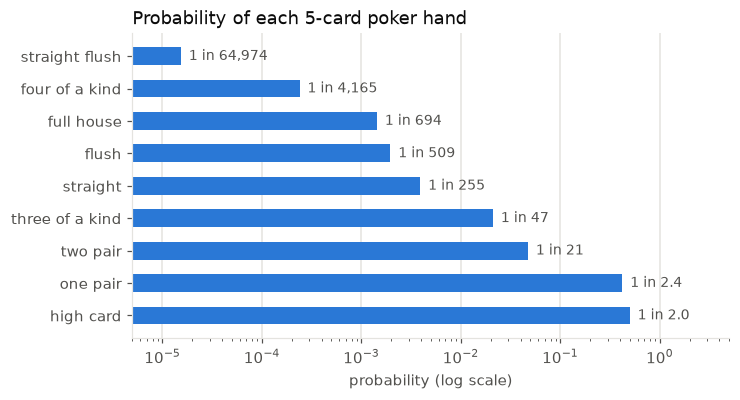

In [21]:
names = list(counts)
probs = np.array([counts[h] / N_HANDS for h in names])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(names, probs, height=0.55, color=BLUE)
for y, p in enumerate(probs):
    label = f"1 in {1 / p:,.0f}" if 1 / p >= 10 else f"1 in {1 / p:.1f}"
    ax.text(p * 1.2, y, label, va="center", color=MUTED, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(5e-6, 5)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("probability (log scale)")
ax.set_title("Probability of each 5-card poker hand", color=INK, loc="left")
plt.show()

## 11. Checking two hands by simulation

**Plan.** Deal many random hands by shuffling a full deck for each hand and keeping the top 5 cards. Classify each hand, then compare the simulated frequencies of **straight** and **two pair** with the exact values from Section 10.

Card number $c$ has rank index $c \bmod 13$ (0 is a deuce, 12 is an ace) and suit index $\lfloor c/13 \rfloor$.

In [22]:
def deal_hands(n, rng, chunk=50_000):
    # Shuffle a fresh deck for each hand and keep the top 5 cards.
    hands = []
    for start in range(0, n, chunk):
        decks = np.tile(np.arange(52), (min(chunk, n - start), 1))
        hands.append(rng.permuted(decks, axis=1)[:, :5])
    return np.vstack(hands)

In [23]:
def classify(hands):
    # Name the poker category of each row of 5 card numbers.
    ranks = np.sort(hands % 13, axis=1)
    suits = hands // 13
    flush = (suits == suits[:, [0]]).all(axis=1)
    rank_counts = (ranks[:, :, None] == np.arange(13)).sum(axis=1)
    top2 = -np.sort(-rank_counts, axis=1)[:, :2]          # two largest multiplicities
    wheel = (ranks == [0, 1, 2, 3, 12]).all(axis=1)        # A-2-3-4-5
    straight = (top2[:, 0] == 1) & ((ranks[:, 4] - ranks[:, 0] == 4) | wheel)

    cat = np.full(len(hands), "high card", dtype=object)
    cat[top2[:, 0] == 2] = "one pair"
    cat[(top2[:, 0] == 2) & (top2[:, 1] == 2)] = "two pair"
    cat[(top2[:, 0] == 3) & (top2[:, 1] == 1)] = "three of a kind"
    cat[straight & ~flush] = "straight"
    cat[flush & ~straight] = "flush"
    cat[(top2[:, 0] == 3) & (top2[:, 1] == 2)] = "full house"
    cat[top2[:, 0] == 4] = "four of a kind"
    cat[straight & flush] = "straight flush"
    return cat

In [24]:
N_SIM = 500_000
sim_hands = deal_hands(N_SIM, rng)
sim_cat = classify(sim_hands)

for name in ["straight", "two pair"]:
    p = counts[name] / N_HANDS
    p_hat = np.mean(sim_cat == name)
    noise = np.sqrt(p * (1 - p) / N_SIM)
    print(f"{name:9s} simulated {p_hat:.5f}   exact {p:.5f}   typical simulation error {noise:.5f}")

straight  simulated 0.00381   exact 0.00392   typical simulation error 0.00009
two pair  simulated 0.04818   exact 0.04754   typical simulation error 0.00030


Both simulated values are within about two typical errors of the exact answer, which is ordinary sampling noise. The yardstick $\sqrt{p(1-p)/N}$ comes from the binomial distribution in Session 5. For completeness, here is every category. The rarest hands appear only a handful of times in 500,000 deals, so their simulated frequencies are noisy.

In [25]:
labels, k = np.unique(sim_cat, return_counts=True)
sim_freq = dict(zip(labels, k / N_SIM))
for name in counts:
    print(f"{name:15s} simulated {sim_freq.get(name, 0):.6f}   exact {counts[name] / N_HANDS:.6f}")

straight flush  simulated 0.000022   exact 0.000015
four of a kind  simulated 0.000250   exact 0.000240
full house      simulated 0.001306   exact 0.001441
flush           simulated 0.001916   exact 0.001965
straight        simulated 0.003810   exact 0.003925
three of a kind simulated 0.021384   exact 0.021128
two pair        simulated 0.048176   exact 0.047539
one pair        simulated 0.421714   exact 0.422569
high card       simulated 0.501422   exact 0.501177


## 12. Quiz: is the queen of hearts in the hand? (slide 12)

**Question.** What is the probability that a random 5-card hand contains the queen of hearts?

**Method 1: one-to-one correspondence.** Removing the queen from a hand that contains it leaves a 4-card hand drawn from the other 51 cards, and adding the queen back reverses this. So the hands containing the queen are in one-to-one correspondence with the 4-card subsets of the remaining 51 cards:

$$P(E) = \frac{\binom{51}{4}}{\binom{52}{5}} = \frac{51! / (4! \cdot 47!)}{52! / (5! \cdot 47!)} = \frac{51! \cdot 5!}{52! \cdot 4!} = \frac{5}{52}.$$

**Method 2: symmetry.** Shuffle the deck and deal the top 5 cards. The queen of hearts is equally likely to sit in any of the 52 positions, and 5 of those positions form the hand, so $P(E) = 5/52$ in one line. The brute-force computation is not needed.

**Method 3: ordered counting.** Count ordered 5-card deals: $52 \cdot 51 \cdot 50 \cdot 49 \cdot 48$ in total. In those containing the queen, choose her position (5 ways) and fill the other 4 positions in order from 51 cards: $5 \cdot 51 \cdot 50 \cdot 49 \cdot 48$. The ratio is again $5/52$. Ordered and unordered counting agree because the numerator and denominator use the same convention.

**General rule.** A specific card lands in a random $k$-card hand from an $n$-card deck with probability $k/n$.

In [26]:
show("bijection: C(51,4) / C(52,5)    ", Fraction(comb(51, 4), comb(52, 5)))
show("symmetry:  5 / 52               ", Fraction(5, 52))
show("ordered:   5 * 51P4 / 52P5      ", Fraction(5 * perm(51, 4), perm(52, 5)))

bijection: C(51,4) / C(52,5)    : 5/52 = 0.096154
symmetry:  5 / 52               : 5/52 = 0.096154
ordered:   5 * 51P4 / 52P5      : 5/52 = 0.096154


In [27]:
QH = 13 * SUITS.index("hearts") + RANKS.index("Q")
print("card", QH, "is", deck[QH])
p_hat = np.mean((sim_hands == QH).any(axis=1))
print(f"simulated {p_hat:.4f}   exact {5 / 52:.4f}")

card 36 is ('hearts', 'Q')
simulated 0.0956   exact 0.0962


## Common pitfalls

1. **Dividing counts in a space that is not equiprobable.** Sums of two dice, the number of heads in several tosses, and unordered outcomes of dice rolls are not equally likely. Count in the space of ordered outcomes instead.
2. **Mixing conventions.** If the denominator counts unordered hands, the numerator must too. Ordered over unordered gives nonsense.
3. **Same role or different roles.** When two choices are interchangeable (the two ranks in two pair), choose them as a set, $\binom{13}{2}$. When they play different roles (triple rank and pair rank in a full house), choose them in order, $13 \cdot 12$.
4. **Forgetting exclusions in a definition.** A straight or a flush excludes straight flushes. The ace plays high or low, but there is no wraparound.
5. **Dividing by $k!$ when items can repeat.** $52^5 / 5!$ is not even an integer. The "divide by $k!$" step works only when the $k$ items are distinct.

## Key takeaways

- A probability model is a sample space $\Omega$, events $E \subseteq \Omega$, and a probability $P$. Choose $\Omega$ so that the symmetry of the experiment makes its outcomes equally likely.
- In an equiprobable space, $P(E) = |E| / |\Omega|$: probability becomes counting.
- Count in stages with the product rule, and at each stage ask whether order matters and whether repetition is allowed.
- $\binom{n}{k} = \dfrac{n!}{k!(n-k)!}$ counts $k$-subsets; it equals the ordered count divided by $k!$.
- $|\Omega| = \binom{52}{5} = 2{,}598{,}960$ poker hands; a straight has probability $10{,}200 / 2{,}598{,}960 \approx 0.39$ percent.
- One-to-one correspondences and symmetry can replace long computations: a specific card is in a random $k$-card hand with probability $k/n$.
- Next session: combining events (complements, unions, intersections), conditional probability, and independence.